# CRM Coursework – Grouping S&P 500 Stocks
Study period: 1 January 2021 – 1 January 2025 (end date exclusive). Benchmark: S&P 500 index (^GSPC). Price data source: yfinance.

In [1]:
# Setup: imports, folders and package versions
import sys, os
import pandas as pd, numpy as np, yfinance as yf, sklearn, scipy, matplotlib

for folder in ['data/raw', 'data/processed', 'outputs/figures']:
    os.makedirs(folder, exist_ok=True)

versions = pd.Series({
    'python': sys.version.split()[0],
    'pandas': pd.__version__,
    'numpy': np.__version__,
    'yfinance': yf.__version__,
    'scikit-learn': sklearn.__version__,
    'scipy': scipy.__version__,
    'matplotlib': matplotlib.__version__,
}, name='version')
versions.to_csv('outputs/package_versions.csv')
versions

python          3.12.0
pandas           3.1.1
numpy            2.5.5
yfinance         1.8.0
scikit-learn     1.9.1
scipy           1.18.1
matplotlib      3.11.2
Name: version, dtype: str

### 1.1 Ticker Selection
I took the S&P 500 company list from Wikipedia, using the version of the page from 20 November 2026 so the list stays the same if the notebook is re-run.

In [2]:
import requests
from io import StringIO
from datetime import datetime

if os.path.exists("data/raw/sp500_constituents.csv"):
    sp500 = pd.read_csv("data/raw/sp500_constituents.csv")
    sp500["Date added"] = pd.to_datetime(sp500["Date added"])
    revision_id = sp500["Wiki revision"][0]
else:
    headers = {"User-Agent": "Mozilla/5.0"}

    # find the version of the wikipedia page from 20 Nov 2026
    params = {
        "action": "query",
        "prop": "revisions",
        "titles": "List of S&P 500 companies",
        "rvlimit": 1,
        "rvstart": "2026-11-20T23:59:59Z",
        "rvdir": "older",
        "format": "json",
    }
    r = requests.get("https://en.wikipedia.org/w/api.php", params=params, headers=headers)
    pages = r.json()["query"]["pages"]
    revision_id = list(pages.values())[0]["revisions"][0]["revid"]

    url = "https://en.wikipedia.org/w/index.php?title=List_of_S%26P_500_companies&oldid=" + str(revision_id)
    html = requests.get(url, headers=headers).text
    sp500 = pd.read_html(StringIO(html))[0]

    # yfinance needs BRK-B instead of BRK.B
    sp500["Ticker"] = sp500["Symbol"].str.replace(".", "-")

    sp500["Date added"] = pd.to_datetime(sp500["Date added"], errors="coerce")
    sp500["Added after 2021"] = sp500["Date added"] > "2021-01-01"

    sp500["Wiki revision"] = revision_id
    sp500["Downloaded on"] = datetime.now().strftime("%Y-%m-%d %H:%M")
    sp500.to_csv("data/raw/sp500_constituents.csv", index=False)

print("Wikipedia revision:", revision_id)
print("Downloaded on:", sp500["Downloaded on"][0])
print("Number of companies:", len(sp500))
print("Added after 1 Jan 2021:", sp500["Added after 2021"].sum())
sp500.head()

Wikipedia revision: 1384572480
Downloaded on: 2026-11-23 17:47
Number of companies: 503
Added after 1 Jan 2021: 89


,Symbol,Security,GICS Sector,GICS Sub-Industry,Headquarters Location,Date added,CIK,Founded,Ticker,Added after 2021,Wiki revision,Downloaded on
0,MMM,3M,Industrials,Industrial Conglomerates,"Saint Paul, Minnesota",1957-03-04,66740,1902,MMM,False,1384572480,2026-11-23 17:47
1,AOS,A. O. Smith,Industrials,Building Products,"Milwaukee, Wisconsin",2017-07-26,91142,1916,AOS,False,1384572480,2026-11-23 17:47
2,ABT,Abbott Laboratories,Health Care,Health Care Equipment,"North Chicago, Illinois",1957-03-04,1800,1888,ABT,False,1384572480,2026-11-23 17:47
3,ABBV,AbbVie,Health Care,Biotechnology,"North Chicago, Illinois",2012-12-31,1551152,2013 (1888),ABBV,False,1384572480,2026-11-23 17:47
4,ACN,Accenture,Information Technology,IT Consulting & Other Services,"Dublin, Ireland",2011-07-06,1467373,1989,ACN,False,1384572480,2026-11-23 17:47


### Downloading Prices
I used yfinance to download daily data for every company and the S&P 500 index (^GSPC) from 1 January 2021 to 1 January 2025 (the end date isn't included).

In [3]:
tickers = sp500["Ticker"].tolist() + ["^GSPC"]

if os.path.exists("data/raw/prices_adj_close.csv"):
    adj_close = pd.read_csv("data/raw/prices_adj_close.csv", index_col=0, parse_dates=True)
    close = pd.read_csv("data/raw/prices_close.csv", index_col=0, parse_dates=True)
    volume = pd.read_csv("data/raw/volume.csv", index_col=0, parse_dates=True)
else:
    # auto_adjust=False so we get both Close and Adj Close
    data = yf.download(tickers, start="2021-01-01", end="2025-01-01", auto_adjust=False, progress=False)

    adj_close = data["Adj Close"]
    close = data["Close"]
    volume = data["Volume"]

    adj_close.to_csv("data/raw/prices_adj_close.csv")
    close.to_csv("data/raw/prices_close.csv")
    volume.to_csv("data/raw/volume.csv")

failed = [t for t in tickers if adj_close[t].isna().all()]

print("Trading days:", len(adj_close))
print("First day:", adj_close.index[0].date())
print("Last day:", adj_close.index[-1].date())
print("Tickers downloaded:", len(tickers) - len(failed))
print("Tickers with no data:", failed)

Trading days: 1005
First day: 2021-01-04
Last day: 2024-12-31
Tickers downloaded: 499
Tickers with no data: ['FDXF', 'HONA', 'Q', 'SNDK', 'VYLR']


### 1.2 Data Checks
Before calculating anything, I checked the data for duplicate dates, missing values, impossible prices, volume errors and possible unadjusted stock splits. I only kept shares with a complete history for the whole study period, so every share is compared over the same weeks. Nothing was filled in. Shares that failed a check are listed in the exclusion log with the reason.

In [4]:
shares = [t for t in sp500["Ticker"] if t in adj_close.columns]

print("Duplicate dates:", adj_close.index.duplicated().sum())
print("Prices zero or below:", (adj_close[shares] <= 0).sum().sum())
print("Negative volume:", (volume[shares] < 0).sum().sum())

log = []
for t in shares:
    if adj_close[t].isna().all():
        log.append([t, "No data in study period"])
    elif adj_close[t].isna().any() or close[t].isna().any() or volume[t].isna().any():
        first = adj_close[t].first_valid_index().date()
        log.append([t, "Incomplete history (first price " + str(first) + ")"])
    elif (adj_close[t] <= 0).any():
        log.append([t, "Price zero or below"])
    elif (volume[t] <= 0).any():
        log.append([t, "Zero or negative volume"])

exclusion_log = pd.DataFrame(log, columns=["Ticker", "Reason"])
exclusion_log.to_csv("outputs/exclusion_log.csv", index=False)

valid = [t for t in shares if t not in exclusion_log["Ticker"].values]

# look for big one-day jumps that could be unadjusted stock splits
daily_change = close[valid].pct_change()
big_moves = daily_change[daily_change.abs() > 0.5].stack().dropna()

# the benchmark only needs prices, its volume isn't used
print("^GSPC missing prices:", adj_close["^GSPC"].isna().sum())

print("Shares checked:", len(shares))
print("Shares excluded:", len(exclusion_log))
print("Shares kept:", len(valid))
print("Possible split days to review:", len(big_moves))
print(big_moves)
exclusion_log

Duplicate dates: 0
Prices zero or below: 0
Negative volume: 0


^GSPC missing prices: 0
Shares checked: 503
Shares excluded: 17
Shares kept: 486
Possible split days to review: 3
Date            
2023-06-08  CVNA    0.560206
2024-04-11  GL     -0.531402
2024-11-15  BE      0.591867
dtype: float64


,Ticker,Reason
0,APP,Incomplete history (first price 2021-04-15)
1,COIN,Incomplete history (first price 2021-04-14)
2,CEG,Incomplete history (first price 2022-01-19)
3,EXE,Incomplete history (first price 2021-02-10)
4,FDXF,No data in study period
5,FERG,Zero or negative volume
6,GEHC,Incomplete history (first price 2022-12-15)
7,GEV,Incomplete history (first price 2024-03-27)
8,HONA,No data in study period
9,Q,No data in study period


### 1.3 Weekly Returns
I turned the daily adjusted closing prices into Friday-ending weeks, using the last trading price of each week. The first and last weeks were only kept if they were complete, and weeks shortened by a holiday were kept as normal. Weekly return = this week's price / last week's price - 1. The shares and the S&P 500 use exactly the same weeks.

In [5]:
weekly_prices = adj_close[valid + ["^GSPC"]].resample("W-FRI").last()

# keep only weeks that fall fully inside the study period
week_start = weekly_prices.index - pd.Timedelta(days=4)
complete = (week_start >= pd.Timestamp("2021-01-01")) & (weekly_prices.index <= pd.Timestamp("2024-12-31"))
dropped_weeks = weekly_prices.index[~complete]
weekly_prices = weekly_prices[complete]

weekly_returns = weekly_prices.pct_change().iloc[1:]

days_per_week = adj_close["^GSPC"].resample("W-FRI").count()
short_weeks = (days_per_week[weekly_returns.index] < 5).sum()

weekly_prices.to_csv("data/processed/weekly_prices.csv")
weekly_returns.to_csv("data/processed/weekly_returns.csv")

print("Incomplete weeks dropped:", [str(d.date()) for d in dropped_weeks])
print("First week:", weekly_returns.index[0].date())
print("Last week:", weekly_returns.index[-1].date())
print("Weekly observations per share:", len(weekly_returns))
print("Holiday-shortened weeks kept:", short_weeks)
print("Missing weekly returns:", weekly_returns.isna().sum().sum())
weekly_returns[["AAPL", "MSFT", "^GSPC"]].head()

Incomplete weeks dropped: ['2025-01-03']
First week: 2021-01-15
Last week: 2024-12-27
Weekly observations per share: 207
Holiday-shortened weeks kept: 37
Missing weekly returns: 0


,AAPL,MSFT,^GSPC
Date,,,
2021-01-15,-0.037183,-0.031737,-0.014754
2021-01-22,0.093834,0.062544,0.019431
2021-01-29,-0.051125,0.026599,-0.033120
2021-02-05,0.037923,0.044145,0.046467
2021-02-12,-0.010164,0.011519,0.012349


### Mean Weekly Return and Weekly Beta
For each share I took the simple average of its 207 weekly returns. Weekly beta = covariance of the share's weekly returns with the S&P 500's / variance of the S&P 500's weekly returns, using the full period. A beta above 1 means the share tended to move more than the market, below 1 means less.

In [6]:
market = weekly_returns["^GSPC"]

features = pd.DataFrame(index=valid)
features["Mean weekly return"] = weekly_returns[valid].mean()
features["Weekly beta"] = [weekly_returns[t].cov(market) / market.var() for t in valid]
features["Weeks used"] = weekly_returns[valid].count()

features.to_csv("data/processed/features_return_beta.csv")

print("Shares:", len(features))
print("Weeks used per share:", features["Weeks used"].unique())
print("S&P 500 mean weekly return:", round(market.mean(), 5))
print()
print(features[["Mean weekly return", "Weekly beta"]].describe().round(4))
print()
print("Highest beta:")
print(features["Weekly beta"].sort_values().tail(5).round(2))
print()
print("Lowest beta:")
print(features["Weekly beta"].sort_values().head(5).round(2))

Shares: 486
Weeks used per share: [207]
S&P 500 mean weekly return: 0.0024

       Mean weekly return  Weekly beta
count            486.0000     486.0000
mean               0.0029       0.9737
std                0.0027       0.4073
min               -0.0045       0.0555
25%                0.0012       0.6666
50%                0.0026       0.9506
75%                0.0042       1.1795
max                0.0178       3.7786

Highest beta:
TWLO    2.07
NVDA    2.13
COHR    2.14
XYZ     2.50
CVNA    3.78
Name: Weekly beta, dtype: float64

Lowest beta:
GIS    0.06
SJM    0.18
MRK    0.20
BMY    0.23
KHC    0.23
Name: Weekly beta, dtype: float64


### 1.4 Adapted RFM
Here RFM describes trading activity instead of customer purchases. A high-volume day is a day when volume is more than twice the average of the previous 20 trading days (not counting the day itself). The observation date is 31 December 2024, the last trading day in the study period.
- **Recency:** calendar days from the latest high-volume day to the observation date.
- **Frequency:** number of high-volume days in the last 60 trading sessions.
- **Monetary:** total of Close × Volume over the last 60 trading sessions, in USD. This is roughly how much money was traded, not the company's value.

In [7]:
obs_date = adj_close.index[-1]
last_60 = adj_close.index[-60:]

# average volume of the 20 days before each day (not including the day itself)
avg_20 = volume[valid].rolling(20).mean().shift(1)
high_volume = volume[valid] > 2 * avg_20

rfm = pd.DataFrame(index=valid)

recency = []
for t in valid:
    event_days = high_volume.index[high_volume[t]]
    if len(event_days) == 0:
        recency.append(np.nan)
    else:
        recency.append((obs_date - event_days[-1]).days)
rfm["Recency"] = recency

rfm["Frequency"] = high_volume.loc[last_60].sum()

# Close and Volume are both split-adjusted by yfinance, so their product is in USD
rfm["Monetary"] = (close.loc[last_60, valid] * volume.loc[last_60, valid]).sum()

rfm.to_csv("data/processed/features_rfm.csv")

print("Observation date:", obs_date.date())
print("Last 60 sessions:", last_60[0].date(), "to", last_60[-1].date())
print("Days of history per share (need at least 80):", len(adj_close))
print("Shares with no high-volume day:", rfm["Recency"].isna().sum())
print()
print(rfm.describe().round(1))

Observation date: 2024-12-31
Last 60 sessions: 2024-10-07 to 2024-12-31
Days of history per share (need at least 80): 1005
Shares with no high-volume day: 0

       Recency  Frequency      Monetary
count    486.0      486.0  4.860000e+02
mean      20.4        3.0  3.940419e+10
std       21.3        1.3  1.291388e+11
min        4.0        0.0  1.297483e+09
25%       11.0        2.0  1.019517e+10
50%       11.0        3.0  1.668382e+10
75%       14.8        4.0  3.227689e+10
max      222.0        8.0  1.847697e+12


### 1.5 Worked Example: Apple (AAPL)
To show how R, F and M are worked out, here is the full calculation for Apple. Each day's volume is compared with twice the average of the 20 days before it.

In [8]:
example = "AAPL"

worked = pd.DataFrame({
    "Volume": volume[example],
    "Avg previous 20 days": avg_20[example],
    "Threshold (2x avg)": 2 * avg_20[example],
    "High-volume day": high_volume[example],
})
event_days = worked[worked["High-volume day"]]

print("Last 5 high-volume days for", example)
print(event_days.tail(5))
print()

last_event = event_days.index[-1]
print("Recency =", obs_date.date(), "minus", last_event.date(), "=", (obs_date - last_event).days, "days")
print("Frequency = high-volume days in the last 60 sessions =", worked.loc[last_60, "High-volume day"].sum())

traded = close.loc[last_60, example] * volume.loc[last_60, example]
print("Monetary = sum of Close x Volume over the last 60 sessions = $", round(traded.sum() / 1e9, 2), "bn")
print()
print("First 3 of the 60 days:")
pd.DataFrame({"Close": close.loc[last_60, example], "Volume": volume.loc[last_60, example], "Close x Volume": traded}).head(3)

Last 5 high-volume days for AAPL
               Volume  Avg previous 20 days  Threshold (2x avg)  \
Date                                                              
2024-06-21  241805100            74685930.0         149371860.0   
2024-08-05  119548600            55246905.0         110493810.0   
2024-09-20  318679900            47003055.0          94006110.0   
2024-11-25   90152800            43820740.0          87641480.0   
2024-12-20  147495300            45004605.0          90009210.0   

            High-volume day  
Date                         
2024-06-21             True  
2024-08-05             True  
2024-09-20             True  
2024-11-25             True  
2024-12-20             True  

Recency = 2024-12-31 minus 2024-12-20 = 11 days
Frequency = high-volume days in the last 60 sessions = 2
Monetary = sum of Close x Volume over the last 60 sessions = $ 623.3 bn

First 3 of the 60 days:


,Close,Volume,Close x Volume
Date,,,
2024-10-07,221.690002,39505400,8.757952e+09
2024-10-08,225.770004,31855700,7.192062e+09
2024-10-09,229.539993,33591100,7.710501e+09


### Feature Summary
All five features for the 486 shares are combined into one table. Monetary is very skewed, which is handled in the next section. The share count shows how many companies were kept and why the others were dropped.

In [9]:
five = ["Mean weekly return", "Weekly beta", "Recency", "Frequency", "Monetary"]

all_features = features[["Mean weekly return", "Weekly beta"]].join(rfm)
all_features = all_features.join(sp500.set_index("Ticker")[["Security", "GICS Sector"]])
all_features.to_csv("data/processed/features.csv")

summary = all_features[five].describe().T
summary["skew"] = all_features[five].skew()
print(summary.to_string(float_format="{:,.4f}".format))
print()

print("Companies on the list:", len(sp500))
print("Excluded:", len(exclusion_log))
print(exclusion_log["Reason"].str.split(" \\(").str[0].value_counts())
print("Kept for analysis:", len(all_features))

                      count                mean                  std                min                 25%                 50%                 75%                    max    skew
Mean weekly return 486.0000              0.0029               0.0027            -0.0045              0.0012              0.0026              0.0042                 0.0178  0.8675
Weekly beta        486.0000              0.9737               0.4073             0.0555              0.6666              0.9506              1.1795                 3.7786  1.1036
Recency            486.0000             20.4074              21.3424             4.0000             11.0000             11.0000             14.7500               222.0000  3.6458
Frequency          486.0000              2.9897               1.3308             0.0000              2.0000              3.0000              4.0000                 8.0000  0.4247
Monetary           486.0000 39,404,191,889.2078 129,138,833,232.9717 1,297,482,617.0479 10,195,173,392.27

## Task 2: Stock Segmentation
### 2.1 Feature Preparation
I built two separate tables for the same 486 shares: one for risk and return (mean weekly return and weekly beta), and one for trading activity (Recency, Frequency and Monetary). Monetary was extremely skewed, so I applied log1p to it. Recency is also skewed, but only because of a few shares with long gaps between busy days, so I left it as it is. I checked for outliers but kept them, since they are real shares. Each table was then standardised so every feature has the same weight.

Skew:
Mean weekly return     0.87
Weekly beta            1.10
Recency                3.65
Frequency              0.42
Monetary              11.68
log1p Monetary         1.08
dtype: float64

Mean weekly return outliers: 15
Weekly beta outliers: 10
Recency outliers: 115
Frequency outliers: 2
Monetary outliers: 45
log1p Monetary outliers: 13


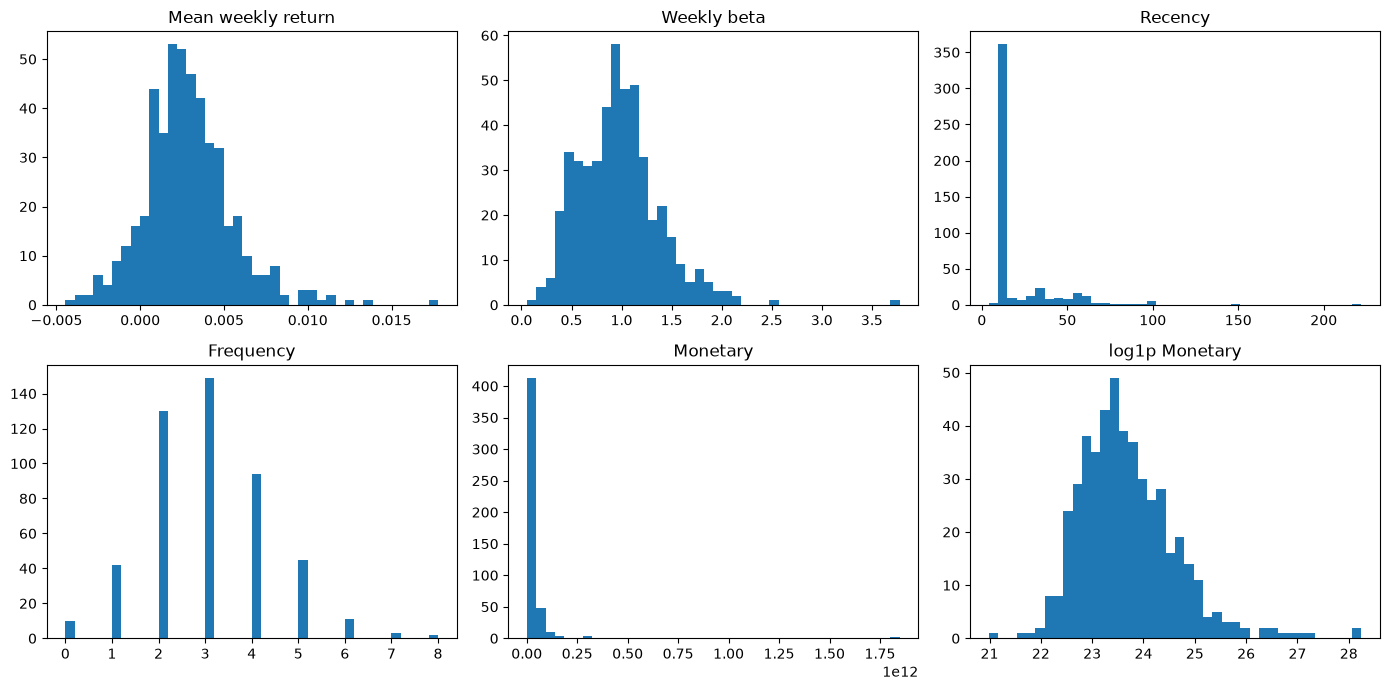

Risk/return table: (486, 2) means [-0. -0.] std [1. 1.]
Activity table: (486, 3) means [-0. -0. -0.] std [1. 1. 1.]


In [10]:
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

all_features["log1p Monetary"] = np.log1p(all_features["Monetary"])

risk_return = all_features[["Mean weekly return", "Weekly beta"]]
activity = all_features[["Recency", "Frequency", "log1p Monetary"]]

# skew before and after the log1p transform
cols = five + ["log1p Monetary"]
print("Skew:")
print(all_features[cols].skew().round(2))
print()

# count outliers with the box-plot rule (more than 1.5 x IQR outside the middle 50%)
for col in cols:
    q1 = all_features[col].quantile(0.25)
    q3 = all_features[col].quantile(0.75)
    iqr = q3 - q1
    outliers = ((all_features[col] < q1 - 1.5 * iqr) | (all_features[col] > q3 + 1.5 * iqr)).sum()
    print(col, "outliers:", outliers)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.flatten(), cols):
    ax.hist(all_features[col], bins=40)
    ax.set_title(col)
plt.tight_layout()
plt.savefig("outputs/figures/feature_distributions.png", dpi=150)
plt.show()

# standardise each table separately
X_risk = StandardScaler().fit_transform(risk_return)
X_activity = StandardScaler().fit_transform(activity)

print("Risk/return table:", X_risk.shape, "means", X_risk.mean(axis=0).round(2), "std", X_risk.std(axis=0).round(2))
print("Activity table:", X_activity.shape, "means", X_activity.mean(axis=0).round(2), "std", X_activity.std(axis=0).round(2))